<a href="https://colab.research.google.com/github/kyleonyonyi-a11y/AI/blob/main/Stroke_Prediction_Final_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stroke Prediction:

In [3]:
# Google Colab only: upload the Kaggle CSV (healthcare-dataset-stroke-data.csv)
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data (2).csv
['healthcare-dataset-stroke-data (2).csv']


---
# PART 1: Data preparation


# 01 Data Preparation: Stroke Prediction



In [42]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', 20)
RANDOM_STATE = 42
FILE = 'healthcare-dataset-stroke-data.csv'
ROOT = Path('..') if Path('../data').exists() else Path('.')
DATA_PATH = next(p for p in [ROOT / 'data' / FILE, Path(FILE)] if p.exists())
PROC = ROOT / 'data' / 'processed'
CHARTS = ROOT / 'charts'
PROC.mkdir(parents=True, exist_ok=True)
CHARTS.mkdir(parents=True, exist_ok=True)
print('Loading:', DATA_PATH)

Loading: healthcare-dataset-stroke-data.csv


## 1. Gather and load the data

In [5]:
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()

Shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 2. Audit the data (before any change)

In [6]:
df.info()
print('\nMissing values per column:\n', df.isnull().sum())
print('\nDuplicate rows (all columns):', df.duplicated().sum())
print('Duplicate rows (ignoring id):', df.drop(columns='id').duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB

Missing values per column:
 id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
eve

In [7]:
print('Target counts:\n', df['stroke'].value_counts())
print('\nTarget share:\n', df['stroke'].value_counts(normalize=True).round(4))
for col in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    print('\n' + col + ':\n', df[col].value_counts())

Target counts:
 stroke
0    4861
1     249
Name: count, dtype: int64

Target share:
 stroke
0    0.9513
1    0.0487
Name: proportion, dtype: float64

gender:
 gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

ever_married:
 ever_married
Yes    3353
No     1757
Name: count, dtype: int64

work_type:
 work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Residence_type:
 Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

smoking_status:
 smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


In [8]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
id,5110.0,36517.83,21161.72,67.00,17741.25,36932.00,54682.00,72940.00
age,5110.0,43.23,22.61,0.08,25.00,45.00,61.00,82.00
hypertension,5110.0,0.10,0.30,0.00,0.00,0.00,0.00,1.00
heart_disease,5110.0,0.05,0.23,0.00,0.00,0.00,0.00,1.00
avg_glucose_level,5110.0,106.15,45.28,55.12,77.24,91.88,114.09,271.74
bmi,4909.0,28.89,7.85,10.30,23.50,28.10,33.10,97.60
stroke,5110.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00


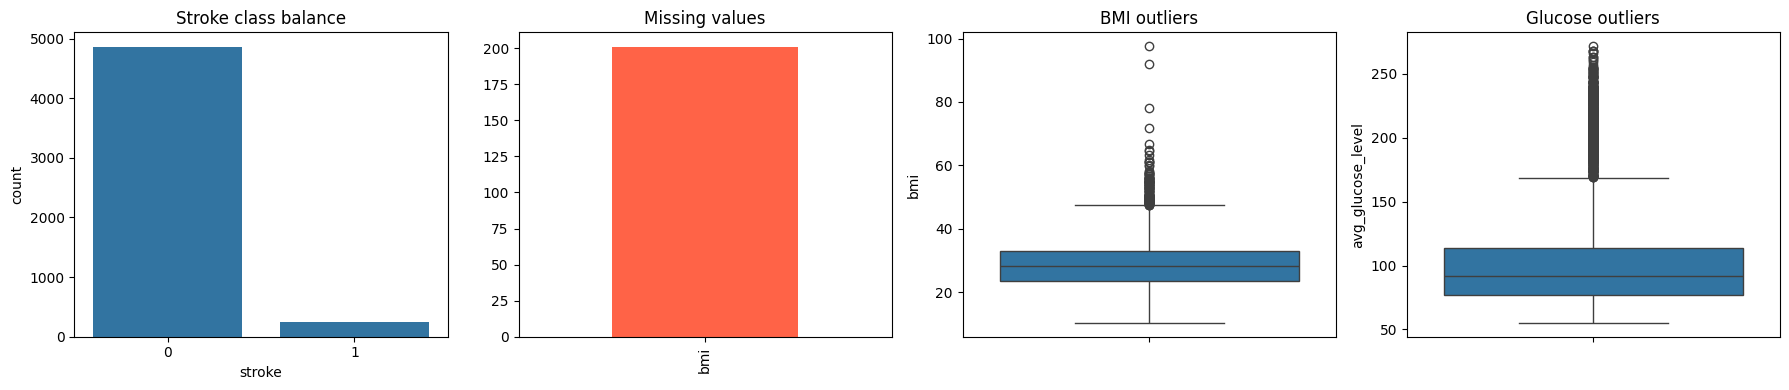

In [9]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
sns.countplot(x='stroke', data=df, ax=ax[0]); ax[0].set_title('Stroke class balance')
df.isnull().sum()[lambda s: s > 0].plot.bar(ax=ax[1], color='tomato'); ax[1].set_title('Missing values')
sns.boxplot(y=df['bmi'], ax=ax[2]); ax[2].set_title('BMI outliers')
sns.boxplot(y=df['avg_glucose_level'], ax=ax[3]); ax[3].set_title('Glucose outliers')
plt.tight_layout()
fig.savefig(CHARTS / '01_audit_overview.png', dpi=130, bbox_inches='tight')
plt.show()

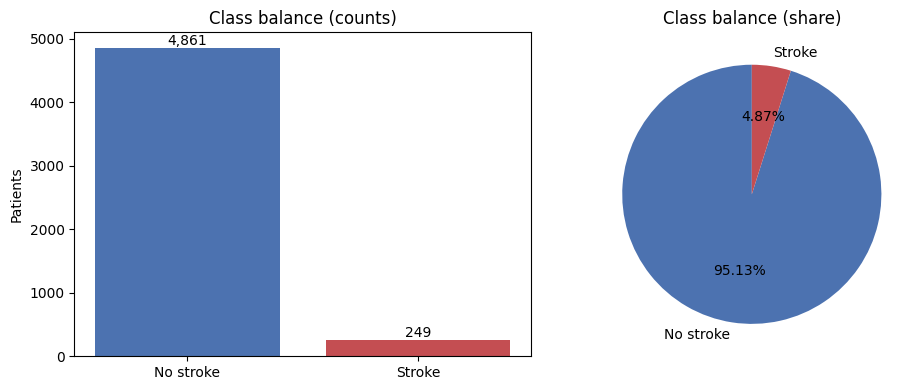

In [10]:
counts = df['stroke'].value_counts().sort_index()
colors = ['#4C72B0', '#C44E52']
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(['No stroke', 'Stroke'], counts.values, color=colors)
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 50, f'{v:,}', ha='center')
ax[0].set_title('Class balance (counts)'); ax[0].set_ylabel('Patients')
ax[1].pie(counts.values, labels=['No stroke', 'Stroke'], autopct='%1.2f%%', colors=colors, startangle=90)
ax[1].set_title('Class balance (share)')
plt.tight_layout()
fig.savefig(CHARTS / '01_class_balance.png', dpi=130, bbox_inches='tight')
plt.show()

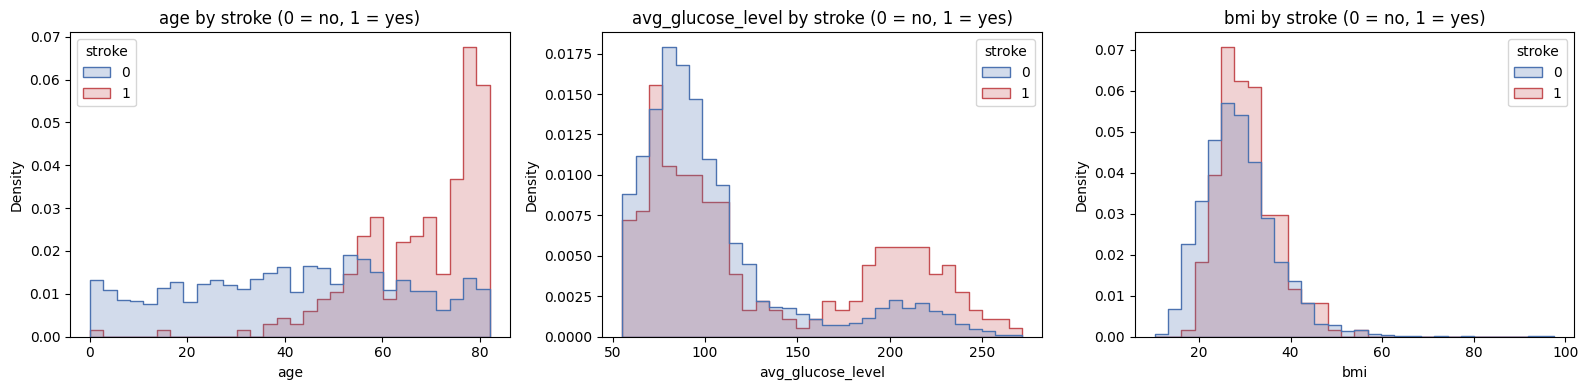

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ['age', 'avg_glucose_level', 'bmi']):
    sns.histplot(data=df, x=col, hue='stroke', stat='density', common_norm=False,
                 bins=30, element='step', palette=['#4C72B0', '#C44E52'], ax=a)
    a.set_title(f'{col} by stroke (0 = no, 1 = yes)')
plt.tight_layout()
fig.savefig(CHARTS / '01_distributions_by_stroke.png', dpi=130, bbox_inches='tight')
plt.show()

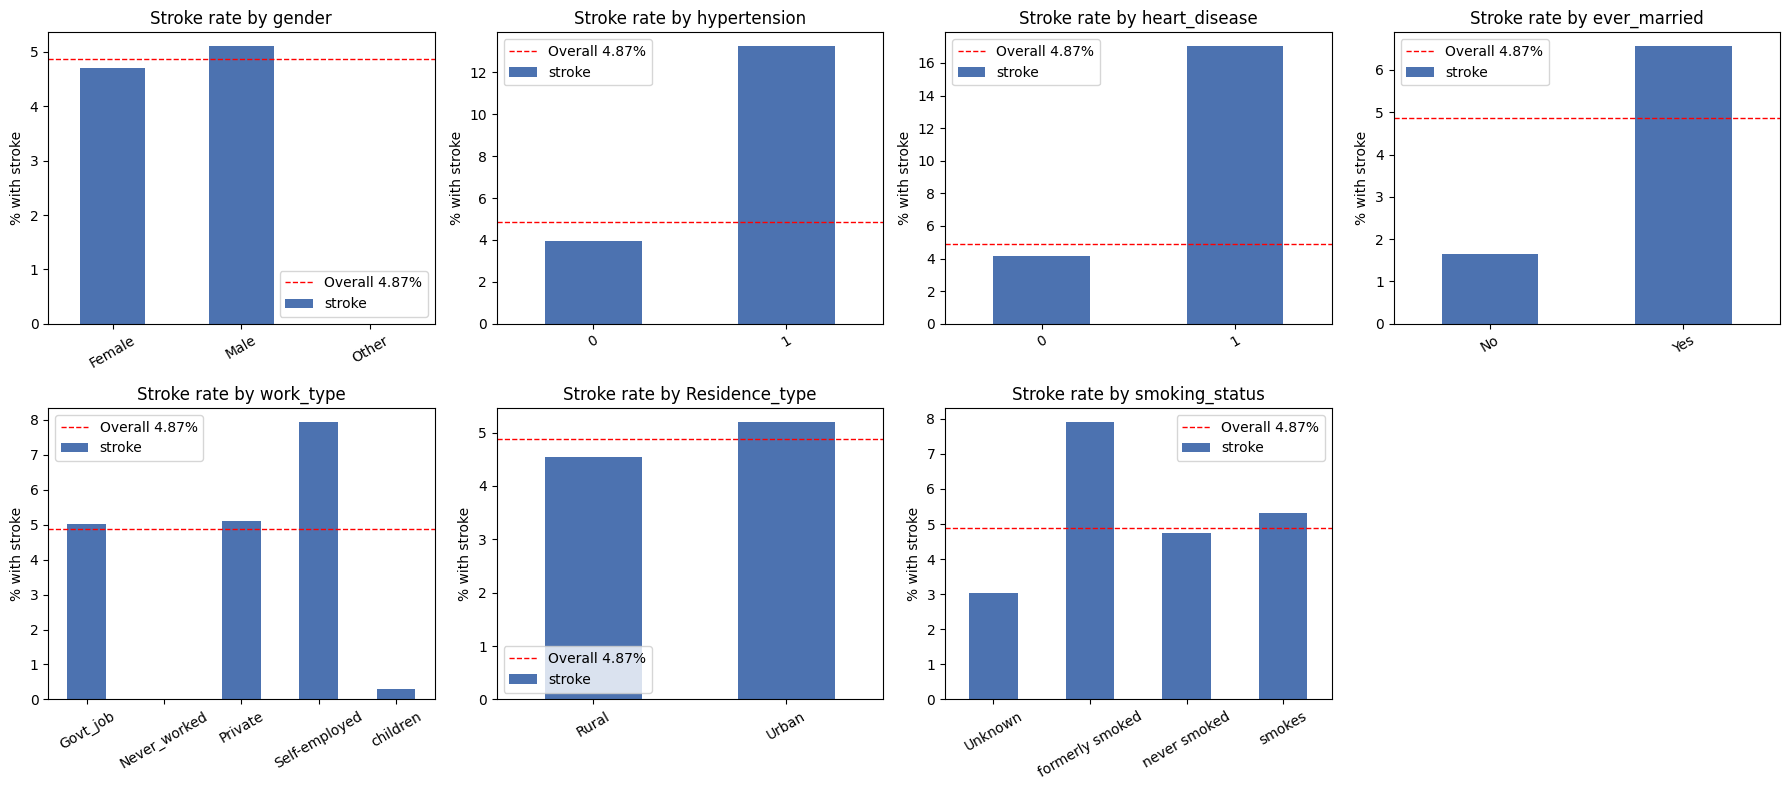

In [12]:
cats = ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
overall = df['stroke'].mean() * 100
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
ax = ax.ravel()
for a, col in zip(ax, cats):
    rate = df.groupby(col)['stroke'].mean() * 100
    rate.plot.bar(ax=a, color='#4C72B0')
    a.axhline(overall, color='red', ls='--', lw=1, label=f'Overall {overall:.2f}%')
    a.set_title(f'Stroke rate by {col}'); a.set_ylabel('% with stroke'); a.set_xlabel('')
    a.tick_params(axis='x', rotation=30); a.legend()
ax[-1].axis('off')
plt.tight_layout()
fig.savefig(CHARTS / '01_stroke_rate_by_category.png', dpi=130, bbox_inches='tight')
plt.show()

### Missing BMI: how big is the problem, and who is affected?

In [13]:
miss = df['bmi'].isnull()
print('Missing BMI rows:', miss.sum(), f'({miss.mean()*100:.2f}% of {len(df):,} rows)')
print('Stroke cases among missing-BMI rows:', df.loc[miss, 'stroke'].sum(), 'of', miss.sum(),
      f'({df.loc[miss, "stroke"].mean()*100:.1f}%)')
print('Stroke rate where BMI present:', f'{df.loc[~miss, "stroke"].mean()*100:.2f}%')
print('Stroke rate where BMI missing:', f'{df.loc[miss, "stroke"].mean()*100:.2f}%')

Missing BMI rows: 201 (3.93% of 5,110 rows)
Stroke cases among missing-BMI rows: 40 of 201 (19.9%)
Stroke rate where BMI present: 4.26%
Stroke rate where BMI missing: 19.90%


          count  median   mean
age_band                      
0-17        836    19.9  21.39
18-39      1278    27.7  29.51
40-59      1510    30.3  31.61
60+        1285    29.2  29.97


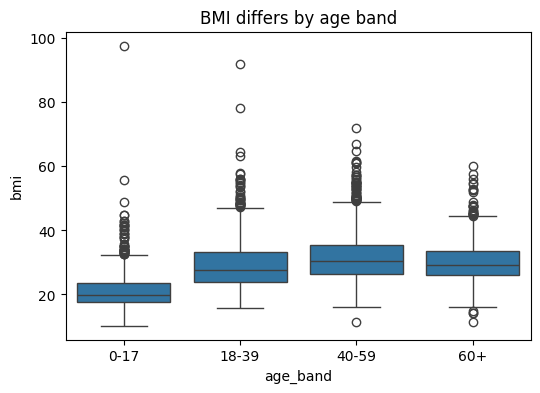

In [14]:
AGE_BINS = [0, 18, 40, 60, 120]
AGE_LABELS = ['0-17', '18-39', '40-59', '60+']
def add_age_band(frame):
    return pd.cut(frame['age'], bins=AGE_BINS, labels=AGE_LABELS, right=False)

# Exploration only: shows why age bands are used. The values used for imputation
# are calculated later from the TRAINING set only.
eda = df.copy()
eda['age_band'] = add_age_band(eda)
print(eda.groupby('age_band', observed=True)['bmi'].agg(['count', 'median', 'mean']).round(2))
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(x='age_band', y='bmi', data=eda, ax=ax)
ax.set_title('BMI differs by age band')
fig.savefig(CHARTS / '01_bmi_by_age_band.png', dpi=130, bbox_inches='tight')
plt.show()

## 3. Clean the data

Drop `id` (identifier only) and the single `gender = Other` row. BMI is imputed later, after the split, so the fill values come from the training set only.

In [15]:
df_clean = df.drop(columns=['id'])
n_other = (df_clean['gender'] == 'Other').sum()
df_clean = df_clean[df_clean['gender'] != 'Other'].reset_index(drop=True)
print('Rows removed (gender = Other):', n_other)
print('Shape after cleaning:', df_clean.shape)
print('Missing BMI still to impute:', df_clean['bmi'].isnull().sum())

Rows removed (gender = Other): 1
Shape after cleaning: (5109, 11)
Missing BMI still to impute: 201


## 4. Encode categorical variables

In [16]:
df_clean['gender'] = df_clean['gender'].map({'Male': 0, 'Female': 1})
df_clean['ever_married'] = df_clean['ever_married'].map({'No': 0, 'Yes': 1})
df_clean['Residence_type'] = df_clean['Residence_type'].map({'Rural': 0, 'Urban': 1})

df_enc = pd.get_dummies(df_clean, columns=['work_type', 'smoking_status'],
                        drop_first=True, dtype=int)
print(df_enc.shape)
df_enc.head()

(5109, 16)


,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,0,67.0,0,1,1,1,228.69,36.6,1,0,1,0,0,1,0,0
1,1,61.0,0,0,1,0,202.21,NaN,1,0,0,1,0,0,1,0
2,0,80.0,0,1,1,0,105.92,32.5,1,0,1,0,0,0,1,0
3,1,49.0,0,0,1,1,171.23,34.4,1,0,1,0,0,0,0,1
4,1,79.0,1,0,1,0,174.12,24.0,1,0,0,1,0,0,1,0


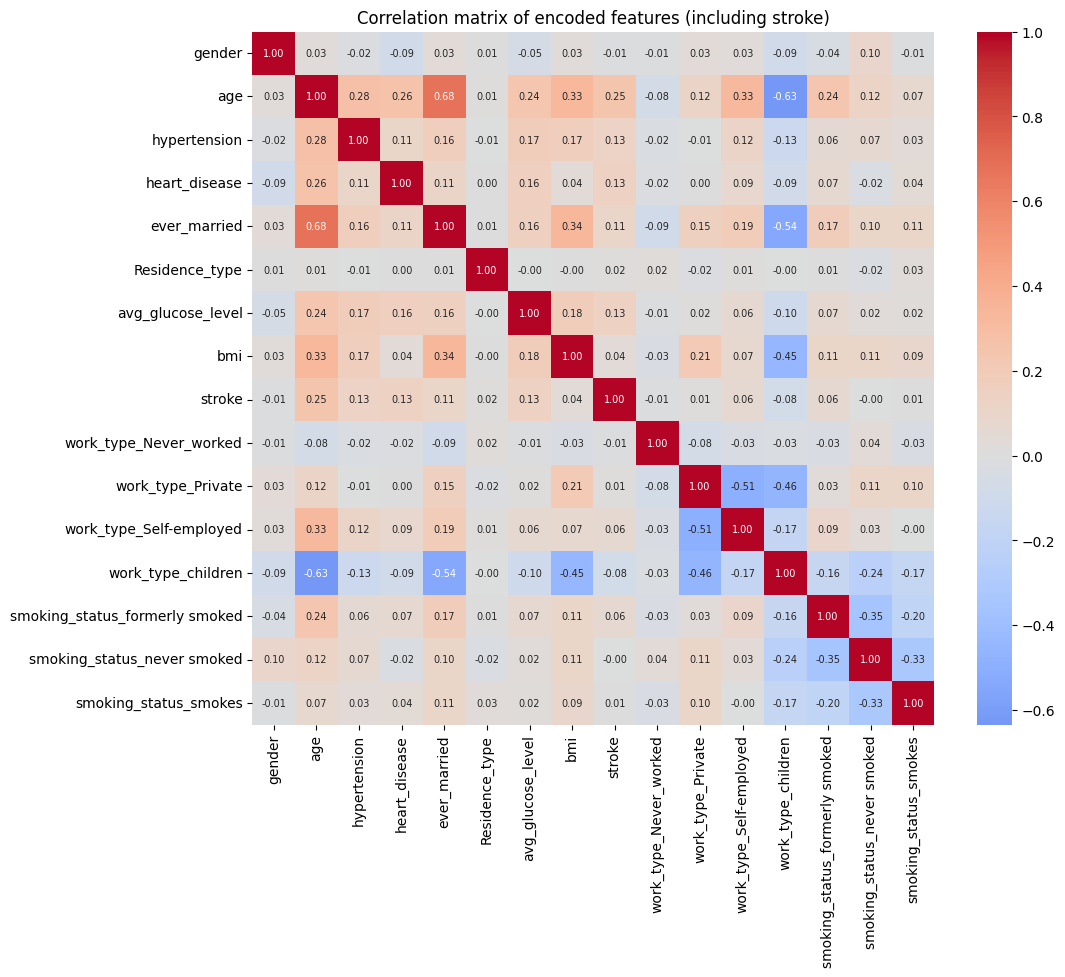

age                               0.245
heart_disease                     0.135
avg_glucose_level                 0.132
hypertension                      0.128
ever_married                      0.108
smoking_status_formerly smoked    0.065
work_type_Self-employed           0.062
bmi                               0.042
Residence_type                    0.015
work_type_Private                 0.012
smoking_status_smokes             0.009
smoking_status_never smoked      -0.004
gender                           -0.009
work_type_Never_worked           -0.015
work_type_children               -0.084
Name: stroke, dtype: float64


In [17]:
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(df_enc.corr(numeric_only=True), cmap='coolwarm', center=0, annot=True, fmt='.2f',
            annot_kws={'size': 7}, ax=ax)
ax.set_title('Correlation matrix of encoded features (including stroke)')
fig.savefig(CHARTS / '01_correlation_heatmap.png', dpi=130, bbox_inches='tight')
plt.show()
print(df_enc.corr(numeric_only=True)['stroke'].drop('stroke').sort_values(ascending=False).round(3))

## 5. Stratified 80/20 train/test split

In [18]:
X = df_enc.drop(columns='stroke')
y = df_enc['stroke']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print('Training set:', X_train.shape, '| Testing set:', X_test.shape)
print('Stroke cases in train / test:', y_train.sum(), '/', y_test.sum())
print('Stroke share in train:', round(y_train.mean() * 100, 2), '%')
print('Stroke share in test :', round(y_test.mean() * 100, 2), '%')

Training set: (4087, 15) | Testing set: (1022, 15)
Stroke cases in train / test: 199 / 50
Stroke share in train: 4.87 %
Stroke share in test : 4.89 %


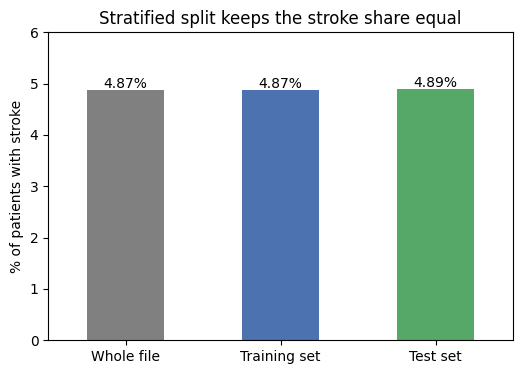

In [19]:
shares = pd.Series({'Whole file': y.mean() * 100, 'Training set': y_train.mean() * 100, 'Test set': y_test.mean() * 100})
fig, ax = plt.subplots(figsize=(6, 4))
shares.plot.bar(ax=ax, color=['grey', '#4C72B0', '#55A868'])
for i, v in enumerate(shares.values):
    ax.text(i, v + 0.05, f'{v:.2f}%', ha='center')
ax.set_ylim(0, 6); ax.set_ylabel('% of patients with stroke'); ax.tick_params(axis='x', rotation=0)
ax.set_title('Stratified split keeps the stroke share equal')
fig.savefig(CHARTS / '01_split_balance.png', dpi=130, bbox_inches='tight')
plt.show()

## 6. Impute missing BMI by age band (training medians only)

In [20]:
for d in (X_train, X_test):
    d['age_band'] = add_age_band(d)

band_median = X_train.groupby('age_band', observed=True)['bmi'].median()
global_median = X_train['bmi'].median()
missing_before = (int(X_train['bmi'].isnull().sum()), int(X_test['bmi'].isnull().sum()))
test_groups = pd.DataFrame({'gender': X_test['gender'].map({0: 'Male', 1: 'Female'}).values,
                            'age_band': X_test['age_band'].astype(str).values})

for d in (X_train, X_test):
    fill = d['age_band'].astype(object).map(band_median).astype(float).fillna(global_median)
    d['bmi'] = d['bmi'].fillna(fill)
    d.drop(columns='age_band', inplace=True)

X_train_imputed = X_train.copy()
print('Age-band medians (training set):')
print(band_median.round(2))
print('Global training median (fallback):', round(global_median, 2))
print('Missing BMI before imputation (train, test):', missing_before)
print('Missing BMI after imputation  (train, test):', X_train['bmi'].isnull().sum(), X_test['bmi'].isnull().sum())

Age-band medians (training set):
age_band
0-17     19.9
18-39    27.7
40-59    30.4
60+      29.4
Name: bmi, dtype: float64
Global training median (fallback): 28.1
Missing BMI before imputation (train, test): (163, 38)
Missing BMI after imputation  (train, test): 0 0


## 7. Scale numeric features

In [21]:
num_cols = ['age', 'avg_glucose_level', 'bmi']
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print('Scaled TRAINING set:')
print(X_train[num_cols].describe().loc[['mean', 'std']].round(3))
print('\nScaled TEST set (transformed with training mean and std):')
print(X_test[num_cols].describe().loc[['mean', 'std']].round(3))

Scaled TRAINING set:
      age  avg_glucose_level  bmi
mean -0.0                0.0  0.0
std   1.0                1.0  1.0

Scaled TEST set (transformed with training mean and std):
        age  avg_glucose_level    bmi
mean -0.006              0.027  0.006
std   0.994              1.067  0.977


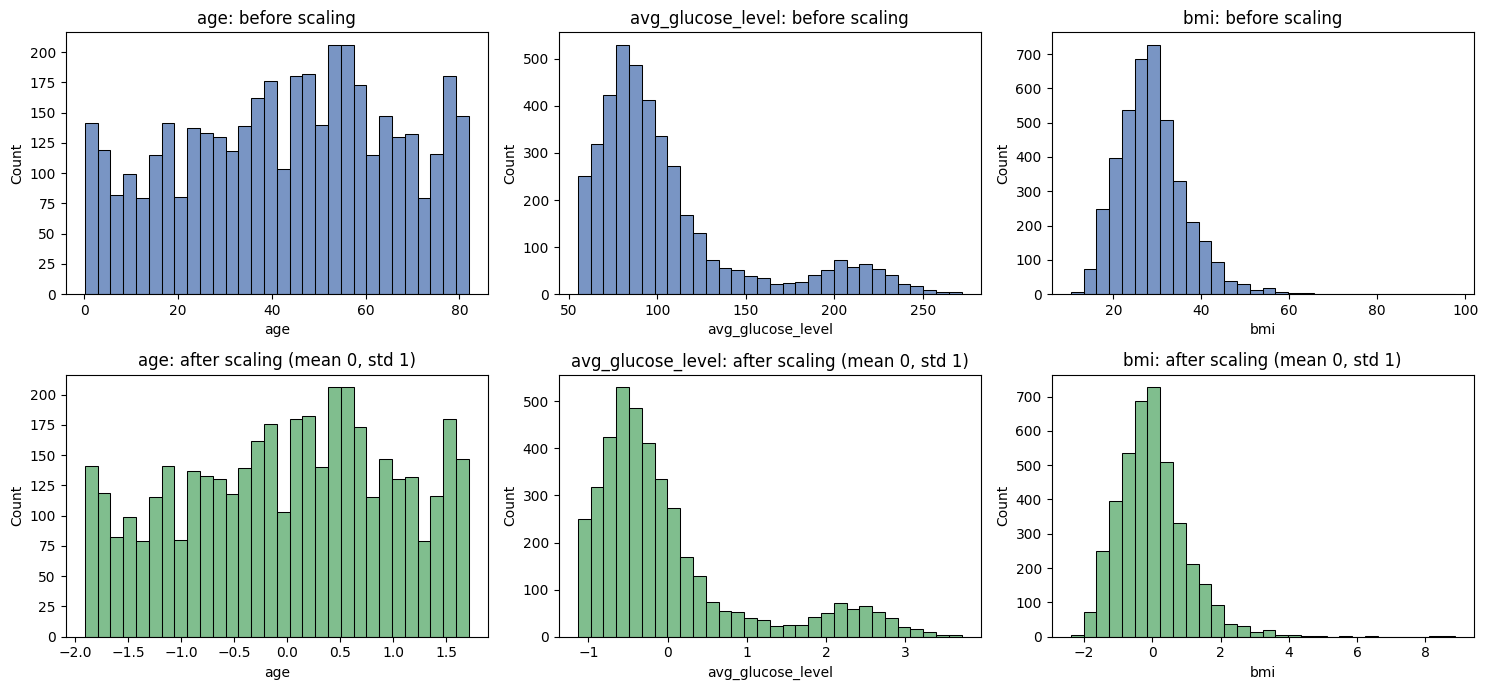

In [22]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for j, col in enumerate(num_cols):
    sns.histplot(X_train_imputed[col], bins=30, ax=ax[0, j], color='#4C72B0')
    ax[0, j].set_title(f'{col}: before scaling')
    sns.histplot(X_train[col], bins=30, ax=ax[1, j], color='#55A868')
    ax[1, j].set_title(f'{col}: after scaling (mean 0, std 1)')
plt.tight_layout()
fig.savefig(CHARTS / '01_scaling_before_after.png', dpi=130, bbox_inches='tight')
plt.show()

## 8. Data quality before and after (M2)

In [23]:
quality = pd.DataFrame({
    'Measure': ['Rows', 'Columns (raw file / model features)', 'Missing BMI values',
                'Text columns', 'Stroke cases', 'Stroke share, training set',
                'Stroke share, test set', 'Duplicate rows'],
    'Before': [df.shape[0], df.shape[1], int(df['bmi'].isnull().sum()),
               int(df.select_dtypes(exclude='number').shape[1]), int(df['stroke'].sum()),
               f'{df["stroke"].mean()*100:.2f}% (whole file)', 'n/a', int(df.duplicated().sum())],
    'After': [df_clean.shape[0], X_train.shape[1],
              int(X_train['bmi'].isnull().sum() + X_test['bmi'].isnull().sum()),
              int(X_train.select_dtypes(exclude='number').shape[1]),
              int(y_train.sum() + y_test.sum()),
              f'{y_train.mean()*100:.2f}%', f'{y_test.mean()*100:.2f}%',
              int(df_clean.duplicated().sum())]})
print(quality.to_string(index=False))

                            Measure             Before After
                               Rows               5110  5109
Columns (raw file / model features)                 12    15
                 Missing BMI values                201     0
                       Text columns                  5     0
                       Stroke cases                249   249
         Stroke share, training set 4.87% (whole file) 4.87%
             Stroke share, test set                n/a 4.89%
                     Duplicate rows                  0     0


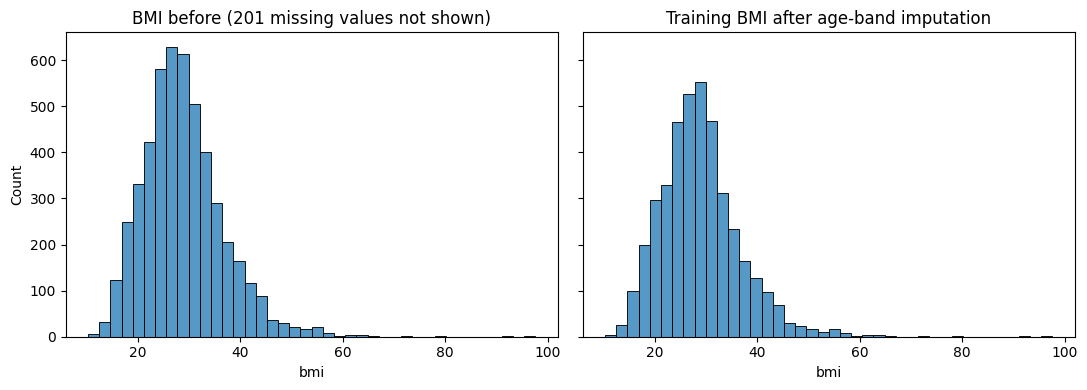

Training BMI median / mean after imputation: 28.2 / 28.87
Original BMI median / mean (non-missing):    28.1 / 28.89


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
sns.histplot(df['bmi'].dropna(), bins=40, ax=ax[0])
ax[0].set_title('BMI before (201 missing values not shown)')
sns.histplot(X_train_imputed['bmi'], bins=40, ax=ax[1])
ax[1].set_title('Training BMI after age-band imputation')
plt.tight_layout()
fig.savefig(CHARTS / '01_bmi_before_after.png', dpi=130, bbox_inches='tight')
plt.show()
print('Training BMI median / mean after imputation:', round(X_train_imputed['bmi'].median(), 2), '/', round(X_train_imputed['bmi'].mean(), 2))
print('Original BMI median / mean (non-missing):   ', round(df['bmi'].median(), 2), '/', round(df['bmi'].mean(), 2))

## 9. Save the prepared data

In [25]:
X_train.to_csv(PROC / 'X_train.csv', index=False)
X_test.to_csv(PROC / 'X_test.csv', index=False)
y_train.to_csv(PROC / 'y_train.csv', index=False)
y_test.to_csv(PROC / 'y_test.csv', index=False)
test_groups.to_csv(PROC / 'test_groups.csv', index=False)
print('Saved to', PROC.resolve())
print(sorted(p.name for p in PROC.iterdir()))

Saved to /content/data/processed
['X_test.csv', 'X_train.csv', 'test_groups.csv', 'y_test.csv', 'y_train.csv']


**Summary.** The data is complete (no missing BMI), numeric, split with the same stroke share in both sets, and scaled using training statistics only. Class imbalance is handled at the model-training stage in notebook 02, and the test set is never resampled.

---
# PART 2: Model building


# 02 Model Building: Logistic Regression for Stroke Prediction




In [26]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve, average_precision_score)

RANDOM_STATE = 42
ROOT = Path('..') if Path('../data').exists() else Path('.')
PROC = ROOT / 'data' / 'processed'
CHARTS = ROOT / 'charts'
CHARTS.mkdir(parents=True, exist_ok=True)

X_train = pd.read_csv(PROC / 'X_train.csv')
X_test = pd.read_csv(PROC / 'X_test.csv')
y_train = pd.read_csv(PROC / 'y_train.csv').squeeze()
y_test = pd.read_csv(PROC / 'y_test.csv').squeeze()
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)
print('Train:', X_train.shape, 'strokes:', int(y_train.sum()))
print('Test :', X_test.shape, 'strokes:', int(y_test.sum()))

baseline = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
baseline.fit(X_train, y_train)
print('Baseline model trained.')

scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.4.6
Train: (4087, 15) strokes: 199
Test : (1022, 15) strokes: 50
Baseline model trained.


In [27]:
def metrics_row(name, y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {'Model': name, 'Threshold': round(float(thr), 2),
            'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn),
            'Accuracy': round(accuracy_score(y_true, pred), 3),
            'Precision': round(precision_score(y_true, pred, zero_division=0), 3),
            'Recall': round(recall_score(y_true, pred), 3),
            'F1': round(f1_score(y_true, pred, zero_division=0), 3),
            'ROC-AUC': round(roc_auc_score(y_true, prob), 3)}

## Baseline results (default settings, threshold 0.5)

In [28]:
y_pred = baseline.predict(X_test)
y_prob = baseline.predict_proba(X_test)[:, 1]

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))
print('ROC-AUC:', round(roc_auc_score(y_test, y_prob), 3))
print('Always-predict-no-stroke accuracy:', round(1 - y_test.mean(), 3))

[[972   0]
 [ 49   1]]
              precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022

ROC-AUC: 0.839
Always-predict-no-stroke accuracy: 0.951


## Refinement 1: class_weight='balanced'

In [29]:
balanced = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)
balanced.fit(X_train, y_train)

prob_bal = balanced.predict_proba(X_test)[:, 1]
pred_bal = (prob_bal >= 0.5).astype(int)
print(confusion_matrix(y_test, pred_bal))
print(classification_report(y_test, pred_bal, zero_division=0))
print('ROC-AUC:', round(roc_auc_score(y_test, prob_bal), 3))

[[714 258]
 [ 10  40]]
              precision    recall  f1-score   support

           0       0.99      0.73      0.84       972
           1       0.13      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.81      1022

ROC-AUC: 0.839


## Refinement 2: decision-threshold search

The threshold is chosen from 5-fold cross-validated predictions on the **training** set (highest precision with recall >= 0.70). The test set is not used to choose it.

Thresholds meeting recall >= 0.70: 58 of 99
Chosen threshold: 0.58
 threshold  precision  recall
      0.54      0.138   0.749
      0.55      0.138   0.734
      0.56      0.140   0.724
      0.57      0.144   0.719
      0.58      0.144   0.709
      0.59      0.146   0.698
      0.60      0.148   0.688
      0.61      0.149   0.678
      0.62      0.150   0.663


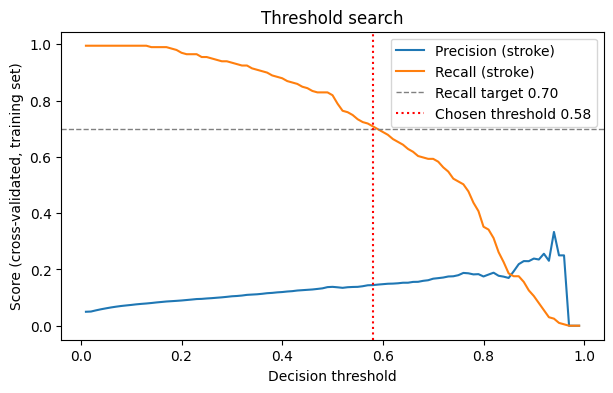

In [30]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof = cross_val_predict(balanced, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

rows = []
for t in np.linspace(0.01, 0.99, 99):
    p = (oof >= t).astype(int)
    rows.append((t, precision_score(y_train, p, zero_division=0), recall_score(y_train, p)))
search = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall'])

ok = search[search['recall'] >= 0.70]
if ok.empty:
    best_t = search.loc[search['recall'].idxmax(), 'threshold']
else:
    best_t = ok.loc[ok['precision'].idxmax(), 'threshold']

print('Thresholds meeting recall >= 0.70:', len(ok), 'of', len(search))
print('Chosen threshold:', round(best_t, 2))
print(search[(search['threshold'] > best_t - 0.045) & (search['threshold'] < best_t + 0.045)].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(search['threshold'], search['precision'], label='Precision (stroke)')
ax.plot(search['threshold'], search['recall'], label='Recall (stroke)')
ax.axhline(0.70, color='grey', ls='--', lw=1, label='Recall target 0.70')
ax.axvline(best_t, color='red', ls=':', label=f'Chosen threshold {best_t:.2f}')
ax.set_xlabel('Decision threshold'); ax.set_ylabel('Score (cross-validated, training set)')
ax.set_title('Threshold search'); ax.legend()
fig.savefig(CHARTS / '02_threshold_search.png', dpi=130, bbox_inches='tight')
plt.show()

In [31]:
pred_tuned = (prob_bal >= best_t).astype(int)
print('Threshold used:', round(best_t, 2))
print(confusion_matrix(y_test, pred_tuned))
print(classification_report(y_test, pred_tuned, zero_division=0))

Threshold used: 0.58
[[770 202]
 [ 10  40]]
              precision    recall  f1-score   support

           0       0.99      0.79      0.88       972
           1       0.17      0.80      0.27        50

    accuracy                           0.79      1022
   macro avg       0.58      0.80      0.58      1022
weighted avg       0.95      0.79      0.85      1022



## Results table (test set)

In [32]:
results = pd.DataFrame([
    metrics_row('Baseline', y_test, y_prob, 0.5),
    metrics_row('Class-weighted', y_test, prob_bal, 0.5),
    metrics_row('Weighted + tuned threshold', y_test, prob_bal, best_t)])
print(results.to_string(index=False))
print('\nAlways-predict-no-stroke accuracy:', round(1 - y_test.mean(), 3))
print('Stroke base rate in test set:', round(y_test.mean(), 4))
print('Precision lift of final model over base rate:', round(results.loc[2, 'Precision'] / y_test.mean(), 2), 'x')
results.to_csv(CHARTS / '02_results_table.csv', index=False)

                     Model  Threshold  TP  FP  FN  TN  Accuracy  Precision  Recall    F1  ROC-AUC
                  Baseline       0.50   1   0  49 972     0.952      1.000    0.02 0.039    0.839
            Class-weighted       0.50  40 258  10 714     0.738      0.134    0.80 0.230    0.839
Weighted + tuned threshold       0.58  40 202  10 770     0.793      0.165    0.80 0.274    0.839

Always-predict-no-stroke accuracy: 0.951
Stroke base rate in test set: 0.0489
Precision lift of final model over base rate: 3.37 x


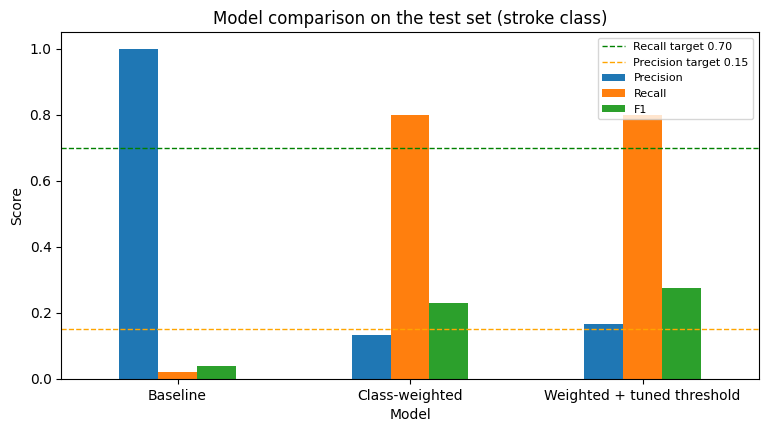

In [33]:
plot_df = results.set_index('Model')[['Precision', 'Recall', 'F1']]
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_df.plot.bar(ax=ax, rot=0)
ax.axhline(0.70, color='green', ls='--', lw=1, label='Recall target 0.70')
ax.axhline(0.15, color='orange', ls='--', lw=1, label='Precision target 0.15')
ax.set_ylim(0, 1.05); ax.set_ylabel('Score'); ax.set_title('Model comparison on the test set (stroke class)')
ax.legend(loc='upper right', fontsize=8)
fig.savefig(CHARTS / '02_model_comparison.png', dpi=130, bbox_inches='tight')
plt.show()

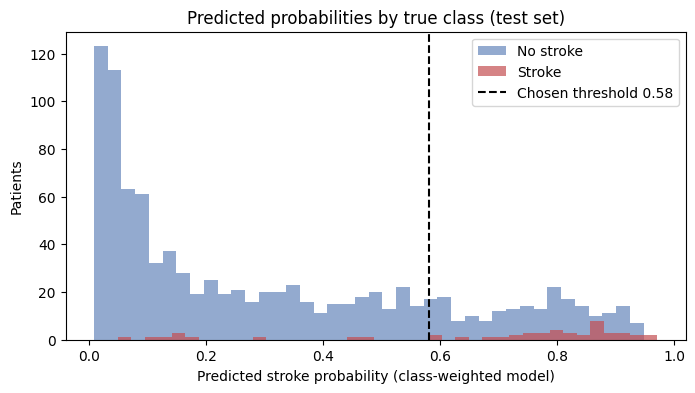

In [34]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(prob_bal[y_test == 0], bins=40, alpha=0.6, label='No stroke', color='#4C72B0')
ax.hist(prob_bal[y_test == 1], bins=40, alpha=0.7, label='Stroke', color='#C44E52')
ax.axvline(best_t, color='k', ls='--', label=f'Chosen threshold {best_t:.2f}')
ax.set_xlabel('Predicted stroke probability (class-weighted model)'); ax.set_ylabel('Patients')
ax.set_title('Predicted probabilities by true class (test set)'); ax.legend()
fig.savefig(CHARTS / '02_probability_distribution.png', dpi=130, bbox_inches='tight')
plt.show()

## Charts

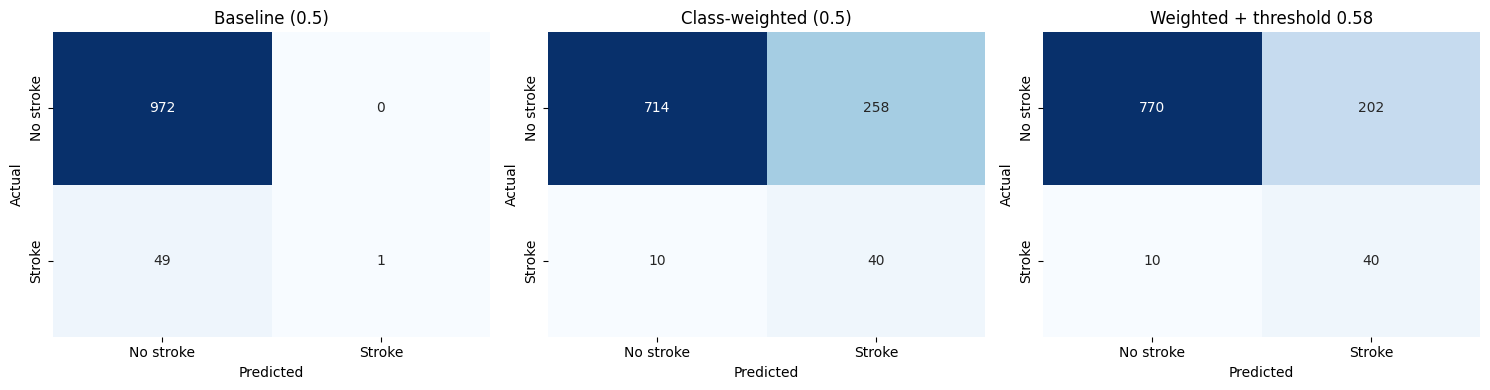

In [35]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (title, pred) in zip(ax, [('Baseline (0.5)', y_pred), ('Class-weighted (0.5)', pred_bal),
                                  (f'Weighted + threshold {best_t:.2f}', pred_tuned)]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt='d', cmap='Blues', cbar=False, ax=a,
                xticklabels=['No stroke', 'Stroke'], yticklabels=['No stroke', 'Stroke'])
    a.set_title(title); a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout()
fig.savefig(CHARTS / '02_confusion_matrices.png', dpi=130, bbox_inches='tight')
plt.show()

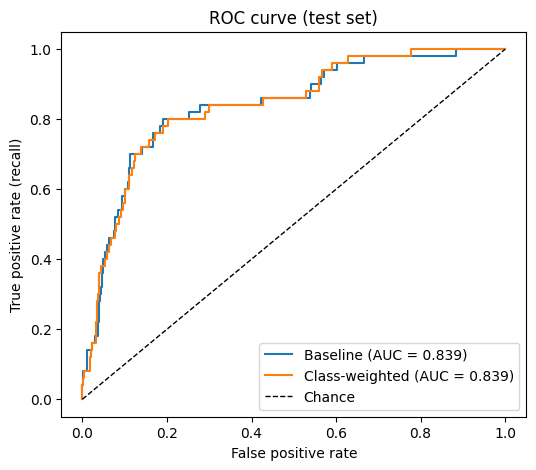

Note: the tuned threshold changes the operating point, not the ROC curve.


In [36]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, prob in [('Baseline', y_prob), ('Class-weighted', prob_bal)]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, prob):.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Chance')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate (recall)')
ax.set_title('ROC curve (test set)'); ax.legend()
fig.savefig(CHARTS / '02_roc_curve.png', dpi=130, bbox_inches='tight')
plt.show()
print('Note: the tuned threshold changes the operating point, not the ROC curve.')

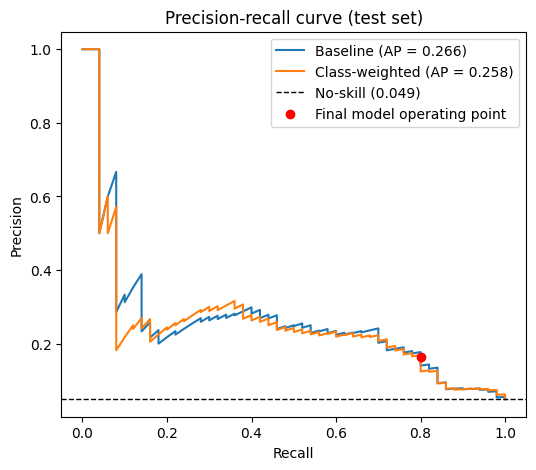

In [37]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, prob in [('Baseline', y_prob), ('Class-weighted', prob_bal)]:
    p, r, _ = precision_recall_curve(y_test, prob)
    ax.plot(r, p, label=f'{name} (AP = {average_precision_score(y_test, prob):.3f})')
ax.axhline(y_test.mean(), color='k', ls='--', lw=1, label=f'No-skill ({y_test.mean():.3f})')
ax.scatter([results.loc[2, 'Recall']], [results.loc[2, 'Precision']], color='red', zorder=5,
           label='Final model operating point')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('Precision-recall curve (test set)')
ax.legend()
fig.savefig(CHARTS / '02_precision_recall_curve.png', dpi=130, bbox_inches='tight')
plt.show()

## Odds ratios (H3)

Odds ratios (class-weighted model; numeric features per 1 standard deviation):
age                               6.586
work_type_children                2.455
hypertension                      1.868
smoking_status_smokes             1.331
avg_glucose_level                 1.233
Residence_type                    1.189
heart_disease                     1.153
gender                            1.144
smoking_status_formerly smoked    1.094
bmi                               1.079
work_type_Private                 1.024
work_type_Never_worked            0.923
ever_married                      0.843
work_type_Self-employed           0.813
smoking_status_never smoked       0.791
dtype: float64


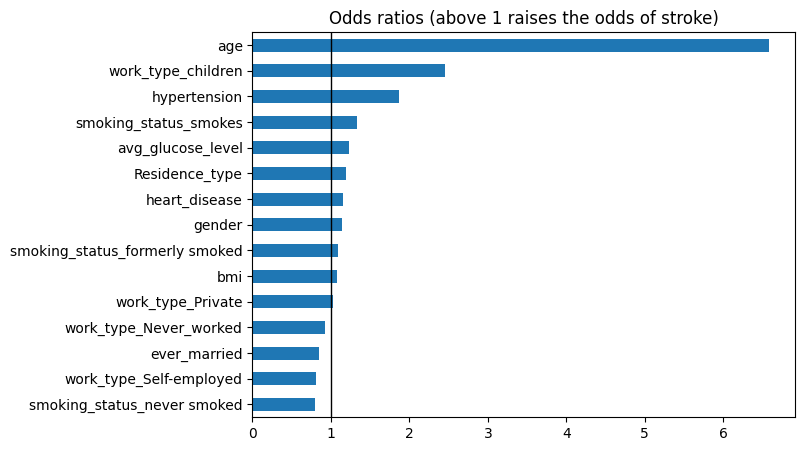

In [38]:
coef = pd.Series(balanced.coef_[0], index=X_train.columns)
odds = np.exp(coef).sort_values(ascending=False).round(3)
print('Odds ratios (class-weighted model; numeric features per 1 standard deviation):')
print(odds)

fig, ax = plt.subplots(figsize=(7, 5))
odds.sort_values().plot.barh(ax=ax)
ax.axvline(1, color='k', lw=1)
ax.set_title('Odds ratios (above 1 raises the odds of stroke)')
fig.savefig(CHARTS / '02_odds_ratios.png', dpi=130, bbox_inches='tight')
plt.show()

## Sampling uncertainty (bootstrap)

In [39]:
rng = np.random.default_rng(RANDOM_STATE)
rec, prec = [], []
y_arr = y_test.to_numpy()
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    rec.append(recall_score(y_arr[idx], pred_tuned[idx]))
    prec.append(precision_score(y_arr[idx], pred_tuned[idx], zero_division=0))
print('Final model, recall    95% CI:', np.percentile(rec, [2.5, 97.5]).round(3))
print('Final model, precision 95% CI:', np.percentile(prec, [2.5, 97.5]).round(3))
print('One stroke case changes recall by about', round(1 / int(y_test.sum()), 3))

Final model, recall    95% CI: [0.686 0.911]
Final model, precision 95% CI: [0.12  0.211]
One stroke case changes recall by about 0.02


## Fairness check: performance by group (final model)

In [40]:
groups = pd.read_csv(PROC / 'test_groups.csv')
rows = []
for col in ['gender', 'age_band']:
    for g, idx in groups.groupby(col).groups.items():
        idx = np.array(idx)
        yt, yp = y_test.iloc[idx], pred_tuned[idx]
        rows.append({'Group': f'{col} = {g}', 'n': len(idx), 'Strokes': int(yt.sum()),
                     'Flagged': int(yp.sum()),
                     'Recall': round(recall_score(yt, yp), 3) if yt.sum() > 0 else float('nan'),
                     'Precision': round(precision_score(yt, yp, zero_division=0), 3)})
print(pd.DataFrame(rows).to_string(index=False))

           Group   n  Strokes  Flagged  Recall  Precision
 gender = Female 597       29      142   0.828      0.169
   gender = Male 425       21      100   0.762      0.160
 age_band = 0-17 173        1        0   0.000      0.000
age_band = 18-39 261        4        0   0.000      0.000
age_band = 40-59 313        7       23   0.286      0.087
  age_band = 60+ 275       38      219   1.000      0.174


## How data-preparation choices affected the results (supports D2)

Each variant uses the same stratified split (same test set) and a class-weighted Logistic Regression at threshold 0.5.

In [41]:
raw = pd.read_csv(ROOT / 'data' / 'healthcare-dataset-stroke-data.csv') if (ROOT / 'data' / 'healthcare-dataset-stroke-data.csv').exists() else pd.read_csv('healthcare-dataset-stroke-data.csv')
BINS, LABELS = [0, 18, 40, 60, 120], ['0-17', '18-39', '40-59', '60+']

def build_and_score(label, impute='ageband', scale=True):
    d = raw.drop(columns='id')
    d = d[d['gender'] != 'Other'].reset_index(drop=True)
    d['gender'] = d['gender'].map({'Male': 0, 'Female': 1})
    d['ever_married'] = d['ever_married'].map({'No': 0, 'Yes': 1})
    d['Residence_type'] = d['Residence_type'].map({'Rural': 0, 'Urban': 1})
    d = pd.get_dummies(d, columns=['work_type', 'smoking_status'], drop_first=True, dtype=int)
    X, y = d.drop(columns='stroke'), d['stroke']
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
    Xtr, Xte = Xtr.copy(), Xte.copy()
    band = lambda f: pd.cut(f['age'], bins=BINS, labels=LABELS, right=False).astype(object)
    med = Xtr.assign(b=band(Xtr)).groupby('b')['bmi'].median()
    gmed = Xtr['bmi'].median()
    def fill_band(f): return f['bmi'].fillna(band(f).map(med).astype(float)).fillna(gmed)
    if impute == 'global':
        Xtr['bmi'] = Xtr['bmi'].fillna(gmed); Xte['bmi'] = Xte['bmi'].fillna(gmed)
    elif impute == 'drop':
        keep = Xtr['bmi'].notna()
        Xtr, ytr = Xtr[keep], ytr[keep]
        Xte['bmi'] = fill_band(Xte)
    else:
        Xtr['bmi'] = fill_band(Xtr); Xte['bmi'] = fill_band(Xte)
    if scale:
        sc = StandardScaler(); cols = ['age', 'avg_glucose_level', 'bmi']
        Xtr[cols] = sc.fit_transform(Xtr[cols]); Xte[cols] = sc.transform(Xte[cols])
    m = LogisticRegression(class_weight='balanced', max_iter=5000, random_state=RANDOM_STATE).fit(Xtr, ytr)
    prob = m.predict_proba(Xte)[:, 1]; pred = (prob >= 0.5).astype(int)
    return {'Variant': label, 'Train rows': len(Xtr), 'ROC-AUC': round(roc_auc_score(yte, prob), 3),
            'Recall@0.5': round(recall_score(yte, pred), 3), 'Precision@0.5': round(precision_score(yte, pred, zero_division=0), 3)}

sens = pd.DataFrame([
    build_and_score('Age-band median + scaling (chosen)'),
    build_and_score('Global median + scaling', impute='global'),
    build_and_score('Drop training rows with missing BMI', impute='drop'),
    build_and_score('Age-band median, NO scaling', scale=False)])
print(sens.to_string(index=False))

                            Variant  Train rows  ROC-AUC  Recall@0.5  Precision@0.5
 Age-band median + scaling (chosen)        4087    0.839         0.8          0.134
            Global median + scaling        4087    0.839         0.8          0.135
Drop training rows with missing BMI        3924    0.834         0.8          0.134
        Age-band median, NO scaling        4087    0.839         0.8          0.134
